# Closing the gap to unseen participants

Part 2 found that every model reaches 0.71 to 0.74 accuracy on a participant it has not seen but 0.86 to
0.91 on participants it has, and that most mistakes are correct repetitions flagged as incorrect. This
notebook tests three ways of attacking that gap, one factor at a time:

1. **Normalization**: remove what is specific to a person before the model sees it.
2. **Overfitting controls**: augmentation, stronger regularization, a smaller model.
3. **Both together.**

Loading, features, models and training now come from the `rehab26` package, so this notebook only defines
the experiments. The split is unchanged: one participant is held out as the test set and is not used here;
the other four take turns as the validation participant.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from rehab26.data import load_dataset, participant_folds
from rehab26.features import COORDINATE_FEATURES, build_features, normalize_by_group, relative_to_start
from rehab26.train import Augment, TrainConfig, run_condition, summarize_scores

TEST_PERSON = "Vasil"
SEEDS = (0, 1, 2)
FIG = "../docs/figures"
pd.set_option("display.width", 220)

X, meta = load_dataset(n_frames=64)
FEATURES = build_features(X[..., :3])
FOLDS = participant_folds(meta, TEST_PERSON)
print("sequences:", len(meta), "| folds:", [(v, len(tr), len(va)) for tr, va, v in FOLDS])
print("device:", "cuda" if torch.cuda.is_available() else "cpu")

sequences: 4995 | folds: [('Honza', 2988, 993), ('Mima', 2976, 1005), ('Petra', 2988, 993), ('Terka', 2991, 990)]
device: cuda


## 1. Experiment A: normalization

Two feature sets (scaled coordinates and biomechanical features) and two models (MLP and 1D CNN), each with
three treatments of the input:

- **none**: as in Part 2.
- **start-relative**: every repetition is expressed as change from its own first frames. This needs only
  the repetition itself.
- **per-recording**: every feature is z-scored within each participant's recording of an exercise, using
  all of that recording's repetitions and no labels.

Per-recording normalization uses the validation participant's own unlabeled movements. That is a different
and easier setting than classifying a single repetition from a stranger: it assumes several repetitions
from the person are available first. It also benefits from this dataset's scripted half-correct,
half-incorrect mix, which a real session would not have.

In [2]:
recording = (meta.person + "_" + meta.exercise_id.astype(str)).values
NORMALIZERS = {
    "none": lambda seq: seq,
    "start-relative": relative_to_start,
    "per-recording": lambda seq: normalize_by_group(seq, recording),
}
KEYS = ("scaled", "biomech")
KINDS = ("mlp", "cnn")

all_scores, all_preds = [], []
def run(name, kind, seq, **kwargs):
    s, p, _ = run_condition(name, kind, seq, meta, FOLDS, SEEDS, **kwargs)
    all_scores.append(s); all_preds.append(p)

A_ORDER = []
for kind in KINDS:
    for key in KEYS:
        for norm, fn in NORMALIZERS.items():
            name = f"{kind.upper()} | {key} | {norm}"
            A_ORDER.append(name)
            run(name, kind, fn(FEATURES[key]))

MLP | scaled | none                      val acc 0.708  (28s)


MLP | scaled | start-relative            val acc 0.731  (26s)


MLP | scaled | per-recording             val acc 0.769  (27s)


MLP | biomech | none                     val acc 0.716  (23s)


MLP | biomech | start-relative           val acc 0.723  (23s)


MLP | biomech | per-recording            val acc 0.747  (23s)


... (2 outputs left out)

CNN | scaled | per-recording             val acc 0.763  (38s)


CNN | biomech | none                     val acc 0.725  (38s)


CNN | biomech | start-relative           val acc 0.734  (39s)


CNN | biomech | per-recording            val acc 0.750  (39s)


In [3]:
COLS = ["acc", "acc_std_folds", "acc_std_seeds", "recall", "specificity", "train_loss", "val_loss"]
scores = pd.concat(all_scores)
table_a = summarize_scores(scores, A_ORDER)
display(table_a[COLS].round(3))
print("Validation accuracy per held-out participant:")
display(scores.groupby(["condition", "val_person"]).acc.mean().unstack().reindex(A_ORDER).round(3))

,acc,acc_std_folds,acc_std_seeds,recall,specificity,train_loss,val_loss
condition,,,,,,,
MLP | scaled | none,0.708,0.063,0.005,0.805,0.610,0.259,0.927
MLP | scaled | start-relative,0.731,0.042,0.004,0.801,0.661,0.244,0.891
MLP | scaled | per-recording,0.769,0.036,0.005,0.823,0.715,0.196,0.711
MLP | biomech | none,0.716,0.056,0.007,0.802,0.630,0.179,1.059
MLP | biomech | start-relative,0.723,0.046,0.004,0.795,0.651,0.184,0.988
MLP | biomech | per-recording,0.747,0.020,0.002,0.804,0.690,0.119,0.968
CNN | scaled | none,0.737,0.080,0.015,0.844,0.630,0.157,1.054
CNN | scaled | start-relative,0.734,0.025,0.020,0.830,0.638,0.121,1.093
CNN | scaled | per-recording,0.763,0.044,0.009,0.853,0.672,0.115,0.823


Validation accuracy per held-out participant:


val_person,Honza,Mima,Petra,Terka
condition,,,,
MLP | scaled | none,0.634,0.744,0.774,0.679
MLP | scaled | start-relative,0.686,0.731,0.788,0.720
MLP | scaled | per-recording,0.750,0.804,0.794,0.729
MLP | biomech | none,0.679,0.739,0.784,0.663
MLP | biomech | start-relative,0.666,0.733,0.777,0.717
MLP | biomech | per-recording,0.731,0.742,0.776,0.740
CNN | scaled | none,0.659,0.782,0.825,0.681
CNN | scaled | start-relative,0.724,0.726,0.770,0.715
CNN | scaled | per-recording,0.723,0.786,0.814,0.728


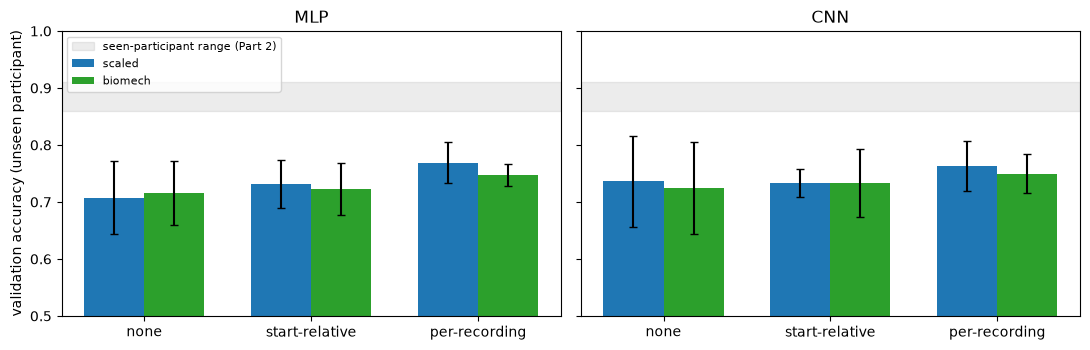

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
xpos = np.arange(len(NORMALIZERS))
for ax, kind in zip(axes, KINDS):
    for off, key, color in [(-0.18, "scaled", "tab:blue"), (0.18, "biomech", "tab:green")]:
        rows = table_a.loc[[f"{kind.upper()} | {key} | {n}" for n in NORMALIZERS]]
        ax.bar(xpos + off, rows.acc, 0.36, yerr=rows.acc_std_folds, capsize=3, color=color, label=key)
    ax.axhspan(0.86, 0.91, color="gray", alpha=0.15, label="seen-participant range (Part 2)")
    ax.set_xticks(xpos); ax.set_xticklabels(list(NORMALIZERS)); ax.set_title(kind.upper()); ax.set_ylim(0.5, 1.0)
axes[0].set_ylabel("validation accuracy (unseen participant)"); axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(f"{FIG}/fig_p3_normalization.png", dpi=150); plt.show()

## 2. Experiment B: overfitting controls

Starting from the Part 2 CNN with no normalization, each row changes one thing:

- **augmentation**: random time warping and noise on every batch, plus random rotation about the vertical
  axis (up to 20°) and scaling (up to 10%) for coordinate features. Biomechanical features are already
  unaffected by rotation and size, so they get time warping and noise only.
- **strong regularization**: dropout 0.5 and ten times the weight decay.
- **small model**: a quarter of the channels.

The `best_epoch_acc` column is the validation accuracy at the best epoch of each run. It is an upper bound
on what early stopping could gain, not a fair score, because it picks the epoch using the validation data.

In [5]:
def make_augment(key):
    if key in COORDINATE_FEATURES:
        return Augment(time_warp=0.5, jitter=0.05, rotate=20, scale=0.1)
    return Augment(time_warp=0.5, jitter=0.05)

CONTROLS = {
    "augmentation": lambda key: dict(augment=make_augment(key)),
    "strong regularization": lambda key: dict(config=TrainConfig(weight_decay=0.1, model_kwargs=dict(dropout=0.5))),
    "small model": lambda key: dict(config=TrainConfig(model_kwargs=dict(widths=(16, 32, 32)))),
}
B_ORDER = []
for key in KEYS:
    B_ORDER.append(f"CNN | {key} | none")            # baseline row from Experiment A
    for label, kwargs in CONTROLS.items():
        name = f"CNN | {key} | {label}"
        B_ORDER.append(name)
        run(name, "cnn", FEATURES[key], **kwargs(key))

scores = pd.concat(all_scores)
table_b = summarize_scores(scores, B_ORDER)
display(table_b[COLS + ["best_epoch_acc"]].round(3))

CNN | scaled | augmentation              val acc 0.724  (50s)


CNN | scaled | strong regularization     val acc 0.732  (41s)


CNN | scaled | small model               val acc 0.718  (41s)


CNN | biomech | augmentation             val acc 0.736  (45s)


CNN | biomech | strong regularization    val acc 0.737  (41s)


CNN | biomech | small model              val acc 0.726  (33s)


,acc,acc_std_folds,acc_std_seeds,recall,specificity,train_loss,val_loss,best_epoch_acc
condition,,,,,,,,
CNN | scaled | none,0.737,0.080,0.015,0.844,0.630,0.157,1.054,0.785
CNN | scaled | augmentation,0.724,0.060,0.003,0.799,0.648,0.248,0.913,0.768
CNN | scaled | strong regularization,0.732,0.073,0.013,0.819,0.645,0.196,0.977,0.765
CNN | scaled | small model,0.718,0.073,0.017,0.784,0.653,0.232,0.971,0.757
CNN | biomech | none,0.725,0.081,0.009,0.828,0.623,0.052,1.549,0.783
CNN | biomech | augmentation,0.736,0.066,0.014,0.834,0.637,0.089,1.330,0.777
CNN | biomech | strong regularization,0.737,0.064,0.016,0.816,0.658,0.087,1.286,0.773
CNN | biomech | small model,0.726,0.066,0.006,0.794,0.658,0.141,1.268,0.769


## 3. Experiment C: normalization and augmentation together

Per-recording normalization combined with augmentation on the CNN. After per-recording normalization the
coordinates are no longer geometric, so only time warping and noise are applied to both feature sets.

In [6]:
C_ORDER = []
for key in KEYS:
    name = f"CNN | {key} | per-recording + augmentation"
    C_ORDER += [f"CNN | {key} | none", f"CNN | {key} | per-recording", name]
    run(name, "cnn", normalize_by_group(FEATURES[key], recording), augment=Augment(time_warp=0.5, jitter=0.05))

scores, preds = pd.concat(all_scores), pd.concat(all_preds)
table_c = summarize_scores(scores, C_ORDER)
display(table_c[COLS].round(3))

CNN | scaled | per-recording + augmentation val acc 0.763  (43s)


CNN | biomech | per-recording + augmentation val acc 0.754  (40s)


,acc,acc_std_folds,acc_std_seeds,recall,specificity,train_loss,val_loss
condition,,,,,,,
CNN | scaled | none,0.737,0.080,0.015,0.844,0.630,0.157,1.054
CNN | scaled | per-recording,0.763,0.044,0.009,0.853,0.672,0.115,0.823
CNN | scaled | per-recording + augmentation,0.763,0.057,0.008,0.838,0.688,0.129,0.811
CNN | biomech | none,0.725,0.081,0.009,0.828,0.623,0.052,1.549
CNN | biomech | per-recording,0.750,0.034,0.009,0.832,0.667,0.033,1.353
CNN | biomech | per-recording + augmentation,0.754,0.038,0.009,0.821,0.686,0.059,1.116


## 4. Where the gains and losses are

The same breakdowns as Part 2 for the baseline and the strongest treatments: accuracy by exercise, accuracy
by viewing angle (negative angles put the exercising arm on the far side from the camera), and the share of
each error type that is caught.

In [7]:
SHOW = ["MLP | biomech | none", "MLP | biomech | per-recording", "CNN | scaled | none",
        "CNN | scaled | per-recording", "CNN | biomech | none", "CNN | biomech | per-recording",
        "CNN | biomech | per-recording + augmentation"]
preds["hit"] = (preds.pred == preds.y).astype(float)
display(preds.groupby(["condition", "exercise"]).hit.mean().unstack().reindex(SHOW).round(3))

preds["view_bin"] = pd.cut(preds["view"], [-91, -60, -30, -1, 30, 60, 91],
                           labels=["-90 to -61", "-60 to -31", "-30 to -1", "0 to 30", "31 to 60", "61 to 90"])
display(preds.groupby(["condition", "view_bin"], observed=True).hit.mean().unstack().reindex(SHOW).round(3))

exercise,Arm abduction,Shoulder extension,Squat
condition,,,
MLP | biomech | none,0.644,0.757,0.748
MLP | biomech | per-recording,0.667,0.791,0.784
CNN | scaled | none,0.668,0.773,0.770
CNN | scaled | per-recording,0.664,0.783,0.843
CNN | biomech | none,0.668,0.778,0.730
CNN | biomech | per-recording,0.668,0.805,0.775
CNN | biomech | per-recording + augmentation,0.695,0.799,0.767


view_bin,-90 to -61,-60 to -31,-30 to -1,0 to 30,31 to 60,61 to 90
condition,,,,,,
MLP | biomech | none,0.663,0.714,0.703,0.723,0.753,0.721
MLP | biomech | per-recording,0.667,0.742,0.755,0.773,0.796,0.677
CNN | scaled | none,0.674,0.752,0.708,0.738,0.775,0.760
CNN | scaled | per-recording,0.651,0.743,0.770,0.826,0.789,0.700
CNN | biomech | none,0.670,0.729,0.703,0.739,0.767,0.704
CNN | biomech | per-recording,0.666,0.755,0.753,0.792,0.768,0.682
CNN | biomech | per-recording + augmentation,0.659,0.748,0.751,0.789,0.788,0.723


In [8]:
PAIR = ["CNN | biomech | none", "CNN | biomech | per-recording"]
inc = preds[preds.y == 1].groupby(["exercise", "error", "condition"]).pred.mean().unstack()[PAIR]
cor = preds[preds.y == 0].groupby(["exercise", "error", "condition"]).pred.apply(lambda s: 1 - s.mean()).unstack()[PAIR]
per_error = pd.concat([cor, inc]).sort_index()
per_error["change"] = per_error[PAIR[1]] - per_error[PAIR[0]]
print(per_error.round(2).to_string())
pd.concat([table_a, table_b, table_c]).drop_duplicates().to_csv("../docs/part3_person_gap_results.csv")

condition                                 CNN | biomech | none  CNN | biomech | per-recording  change
exercise           error                                                                             
Arm abduction      ERR_ARM_FORWARD                        0.76                           0.73   -0.02
                   ERR_BENT_ARM                           0.75                           0.81    0.06
                   ERR_ELEVATED_SHOULDER                  0.75                           0.73   -0.03
                   ERR_HEAD_TO_SIDE                       0.76                           0.77    0.00
                   ERR_LOW_ABDUCTION                      0.88                           0.86   -0.02
                   correct                                0.56                           0.56    0.00
Shoulder extension ERR_ARM_TO_SIDE                        0.61                           0.76    0.15
                   ERR_BENT_ARM                           0.66                    

## 5. Findings

Accuracy is the mean over four held-out participants and three seeds. Seed-to-seed variation is 0.01 to
0.02, so differences of that size are noise.

| Treatment | MLP, scaled | MLP, biomech | CNN, scaled | CNN, biomech |
|:--|:--|:--|:--|:--|
| None (Part 2) | 0.708 | 0.716 | 0.737 | 0.725 |
| Start-relative | 0.731 | 0.723 | 0.734 | 0.734 |
| Per-recording normalization | **0.769** | 0.747 | 0.763 | 0.750 |
| Augmentation | | | 0.724 | 0.736 |
| Strong regularization | | | 0.732 | 0.737 |
| Small model | | | 0.718 | 0.726 |
| Per-recording + augmentation | | | 0.763 | 0.754 |

**Per-recording normalization is the only thing that helps consistently.** It adds 2.5 to 6 points in all
four model and feature combinations, and it halves the spread between participants (from 0.06 to 0.08 down
to 0.02 to 0.04). The gain comes from the two participants the models were worst on, who improve by 5 to 12
points, while the two easier participants stay about the same. It works by reducing false alarms: the share
of correct repetitions that pass rises from about 0.62 to about 0.69.

**It closes only part of the gap.** The best result is 0.77 against 0.86 to 0.91 on seen participants, so
most of the gap remains. It also relies on having many unlabeled repetitions from the new person, in this
dataset's balanced mix of correct and incorrect.

**Start-relative features help the MLP on coordinates a little (about 2 points) and nothing else.**

**None of the overfitting controls improves accuracy.** Augmentation, stronger regularization and a smaller
model all lower the validation loss, but accuracy stays within noise of the baseline, and adding
augmentation on top of normalization adds nothing. The models are not failing because they are too large
or under-regularized. The best-epoch column is 4 to 5 points above the final accuracy, but that number is
chosen using the validation data across 30 noisy epochs, so it overstates what early stopping would give.

**Two problems are untouched by everything tried here.**

- *Arm abduction* stays at 0.66 to 0.70, and only 56% of its correct repetitions pass, with or without
  normalization.
- *Far-side views* (exercising arm hidden from the camera) stay at 0.65 to 0.67. Normalization raises
  frontal views by 5 to 9 points but slightly lowers the opposite side views, probably because one set of
  statistics is shared across all three cameras and all orientations of a recording.

**Normalization trades one kind of mistake for another on squats.** Correct squats pass far more often
(0.55 to 0.70), but three squat errors are caught about 10 points less often.

### What this suggests next

1. **Pose quality is now the more likely limit for arm abduction and far-side views**, since neither
   responds to normalization or regularization. That is the case a stronger pose model could be tested on.
2. **Normalize per recording and camera**, or per orientation block, to see whether the side-view loss
   goes away.
3. **Calibration repetitions.** Normalize a new person using a few repetitions known to be correct. This
   is closer to how a clinician would set up a home program, and does not depend on the balanced mix.
